# OliveSmart — OLV-4 : analyse satellitaire multi-temporelle
## Objectif
Détecter les anomalies de vigueur par **parcelle**, distinctes du cycle saisonnier.
Comparer z-score NDVI, Isolation Forest, One-Class SVM et autoencoder dense à fenêtres
causales. Les anomalies ne constituent pas un diagnostic de maladie.

Ce notebook contient tous les traitements. Les cellules exécutées sans données réelles
documentent les blocages ; elles ne produisent ni entraînement ni scores fictifs.
Les fichiers de l'ancien sujet OLV-6 sont conservés séparément.

In [1]:
from pathlib import Path
import os, json, hashlib, sys, platform, importlib.metadata, random, copy, time
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from torch import nn
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_fscore_support, average_precision_score, roc_auc_score, confusion_matrix
import optuna
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / 'requirements.txt').exists() and (ROOT / 'ai/olv4').exists():
    ROOT = ROOT / 'ai/olv4'
RAW, META, PROCESSED, OUT = [ROOT / p for p in ['data/raw','data/metadata','data/processed','outputs']]
for p in [RAW, META, PROCESSED, OUT]: p.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
# À fixer AVANT extraction et consultation du test. Dates de fin exclusives.
CFG = dict(start='2019-01-01', train_end='2023-01-01', val_end='2024-01-01',
           end='2025-01-01', heldout_basin='', step_days=10, cloud_max=40,
           min_valid_fraction=.6, trials=12, target_alert_rate=.05,
           event_tolerance_days=10, max_gap_days=15, project=os.getenv('EE_PROJECT',''))
# Ces dates sont des paramètres proposés, pas une affirmation de disponibilité.
RUN_EXTRACTION = False  # True après fourniture de parcelles.geojson et activation Earth Engine
RUN_EXPERIMENT = True
print('Configuration proposée :'); display(CFG)

Configuration proposée :


C:\Users\ASUS\Desktop\emsi2\MICROSERVICES\SmartOlive\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'start': '2019-01-01',
 'train_end': '2023-01-01',
 'val_end': '2024-01-01',
 'end': '2025-01-01',
 'heldout_basin': '',
 'step_days': 10,
 'cloud_max': 40,
 'min_valid_fraction': 0.6,
 'trials': 12,
 'target_alert_rate': 0.05,
 'event_tolerance_days': 10,
 'max_gap_days': 15,
 'project': ''}

## Sources et audit
| Source officielle | Usage et limites |
|---|---|
| [Sentinel-2 L2A harmonisé](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED) | Réflectances UINT16 × 0,0001, bandes 10–20 m ; SCL à 20 m pour ombres, nuages, neige et pixels invalides. NDRE utilise B5/B8A. Aucun label de stress. |
| [Landsat Collection 2](https://www.usgs.gov/landsat-missions/landsat-collection-2) | Historique à 30 m ; extraction L8/L9 L2, facteurs 0,0000275 et −0,2, QA_PIXEL et QA_RADSAT. Baseline saisonnière indépendante : pas de NDRE, pas de fusion naïve avec Sentinel. L4–7 nécessiteraient un mappage de bandes distinct. |
| [ERA5-Land](https://developers.google.com/earth-engine/datasets/catalog/ECMWF_ERA5_LAND_DAILY_AGGR) | Température et précipitations ; maille ~11 km, contexte régional, pas mesure locale d'irrigation. Réanalyse disponible avec latence : expérience rétrospective. |
| [Copernicus Data Space](https://dataspace.copernicus.eu/) | Autre accès aux mêmes scènes Sentinel, pas un jeu indépendant à additionner ; téléchargement natif selon compte et zone choisis. |
| Collecte Maroc | Polygones WGS84, identifiants parcelle/exploitation/bassin, visites datées, irrigation, stress et périodes surveillées à fournir. |

Sentinel : conditions Copernicus ; Landsat : politique USGS ; ERA5 : attribution/licence
Copernicus indiquée dans son catalogue. Conserver les pages sources et leurs conditions.
Le volume dépend de la zone et des dates : export de tables par année pour éviter le
téléchargement intégral d'images. Les tailles réelles et SHA-256 locaux sont consignés.
Un hash local ne remplace pas une empreinte publiée par le fournisseur.

In [2]:
SOURCES = {
 'sentinel2':'https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED',
 'landsat':'https://www.usgs.gov/landsat-missions/landsat-collection-2',
 'era5':'https://developers.google.com/earth-engine/datasets/catalog/ECMWF_ERA5_LAND_DAILY_AGGR',
 'copernicus':'https://dataspace.copernicus.eu/'}
def record_file(path, source, url, version, integrity):
    manifest = META / 'manifest.json'
    records = json.loads(manifest.read_text()) if manifest.exists() else []
    item = dict(source=source, version=version, url=url, file=str(path.relative_to(ROOT)),
                bytes=path.stat().st_size, sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
                published_checksum=None, integrity=integrity,
                retrieved_utc=pd.Timestamp.now(tz='UTC').isoformat())
    records = [r for r in records if r['file'] != item['file']] + [item]
    manifest.write_text(json.dumps(records, indent=2, ensure_ascii=False), encoding='utf-8')
for source, url in SOURCES.items():
    dest = META / (source + '.html')
    try:
        if not dest.exists():
            with urlopen(url, timeout=45) as response: dest.write_bytes(response.read())
        record_file(dest, source, url, 'catalogue officiel', 'HTML conservé ; pas une acquisition raster')
        print(source, ': documentation téléchargée', dest.stat().st_size, 'octets')
    except Exception as exc: print(source, ': accès indisponible :', str(exc))
# Schémas vides : aucune géométrie ni vérité terrain inventée.
morocco = RAW / 'maroc'; morocco.mkdir(exist_ok=True)
schemas = {
 'events.csv':['event_id','parcel_id','onset','end','available_at','confirmed'],
 'surveillance.csv':['parcel_id','start','end'],
 'visits.csv':['parcel_id','date','available_at','stress','irrigation','notes']}
for name, cols in schemas.items():
    if not (morocco/name).exists(): pd.DataFrame(columns=cols).to_csv(morocco/name,index=False)
print('GeoJSON requis : FeatureCollection de Polygon/MultiPolygon ; propriétés parcel_id, farm_id, basin.')

sentinel2 : documentation téléchargée 128053 octets
landsat : documentation téléchargée 148939 octets
era5 : documentation téléchargée 148862 octets
copernicus : documentation téléchargée 110976 octets
GeoJSON requis : FeatureCollection de Polygon/MultiPolygon ; propriétés parcel_id, farm_id, basin.


### Extraction officielle Earth Engine et contrôle qualité
Authentification utilisateur : `earthengine authenticate` dans le terminal PyCharm,
puis définir `EE_PROJECT`. Fournir `data/raw/maroc/parcelles.geojson` et activer
`RUN_EXTRACTION`. L'extraction travaille sur les géométries réelles, sans zone exemple.
Les scènes sont masquées avant les indices. NDWI = (vert − proche IR)/(vert + proche IR),
à distinguer de NDMI ; SAVI utilise L=0,5 sur réflectances physiques.
Les indices Sentinel sont réduits à 20 m pour respecter les bandes red-edge/SWIR.
Le taux valide est la surface de pixels valides rapportée au support raster de la parcelle.
Landsat reste dans une table séparée. Une parcelle très petite ou mixte doit être exclue
ou inspectée ; aucune interpolation ni lissage ne masque une rupture.
Les requêtes sont découpées par année et les fichiers terminés réutilisés après contrôle
du hash. Une requête interrompue est relancée entièrement pour son seul lot annuel.

In [3]:
def extract_ee():
    import ee
    if not CFG['project']: raise ValueError('Définir EE_PROJECT : projet Earth Engine autorisé requis.')
    path = morocco/'parcelles.geojson'
    geo = json.loads(path.read_text(encoding='utf-8'))
    assert geo['type']=='FeatureCollection' and geo['features'], 'Polygones réels requis'
    ids = []
    for f in geo['features']:
        assert f['geometry']['type'] in ['Polygon','MultiPolygon']
        assert all(f['properties'].get(k) for k in ['parcel_id','farm_id','basin'])
        ids.append(f['properties']['parcel_id'])
    assert len(ids)==len(set(ids)), 'Identifiants parcelle dupliqués'
    ee.Initialize(project=CFG['project'])
    parcels = ee.FeatureCollection(geo)
    def s2(im):
        scl = im.select('SCL')
        mask = scl.eq(4).Or(scl.eq(5)).Or(scl.eq(6))
        r = im.select(['B3','B4','B5','B8','B8A']).multiply(.0001).updateMask(mask)
        def ratio(a,b): return a.subtract(b).divide(a.add(b)).updateMask(a.add(b).abs().gt(1e-8))
        return ee.Image.cat([
          ratio(r.select('B8'),r.select('B4')).rename('ndvi'),
          ratio(r.select('B8A'),r.select('B5')).rename('ndre'),
          ratio(r.select('B3'),r.select('B8')).rename('ndwi'),
          r.expression('1.5*(n-r)/(n+r+0.5)',{'n':r.select('B8'),'r':r.select('B4')}).rename('savi')
        ]).copyProperties(im,['system:time_start'])
    def ls(im):
        mask = im.select('QA_PIXEL').bitwiseAnd(63).eq(0).And(im.select('QA_RADSAT').eq(0))
        r = im.select(['SR_B4','SR_B5']).multiply(.0000275).add(-.2).updateMask(mask)
        den = r.select('SR_B5').add(r.select('SR_B4'))
        return r.select('SR_B5').subtract(r.select('SR_B4')).divide(den).updateMask(den.abs().gt(1e-8)).rename('ndvi').copyProperties(im,['system:time_start'])
    collections = {
      'sentinel2':ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED').filterBounds(parcels.geometry()).filter(ee.Filter.lte('CLOUDY_PIXEL_PERCENTAGE',CFG['cloud_max'])).map(s2),
      'landsat':ee.ImageCollection('LANDSAT/LC08/C02/T1_L2').merge(ee.ImageCollection('LANDSAT/LC09/C02/T1_L2')).filterBounds(parcels.geometry()).map(ls),
      'era5':ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR').select(['temperature_2m','total_precipitation_sum'])}
    for source, col in collections.items():
        folder = RAW/source; folder.mkdir(exist_ok=True)
        for year in range(pd.Timestamp(CFG['start']).year,pd.Timestamp(CFG['end']).year+1):
            begin=max(pd.Timestamp(CFG['start']),pd.Timestamp(year,1,1))
            finish=min(pd.Timestamp(CFG['end']),pd.Timestamp(year+1,1,1))
            if begin>=finish: continue
            dest=folder/f'{year}.csv'
            if dest.exists():
                records=json.loads((META/'manifest.json').read_text())
                rec=next((r for r in records if r['file']==str(dest.relative_to(ROOT))),None)
                if rec and rec['sha256']==hashlib.sha256(dest.read_bytes()).hexdigest(): continue
            tables=[]
            for start in pd.date_range(begin,finish,freq=f"{CFG['step_days']}D",inclusive='left'):
                end=min(start+pd.Timedelta(days=CFG['step_days']),finish)
                part=col.filterDate(start.strftime('%Y-%m-%d'),end.strftime('%Y-%m-%d'))
                if part.size().getInfo()==0: continue
                if source=='era5':
                    im=ee.Image.cat([part.select('temperature_2m').mean().subtract(273.15).rename('temperature_c'),part.select('total_precipitation_sum').sum().multiply(1000).rename('precipitation_mm')])
                    scale=11132
                else:
                    im=part.median(); scale=20 if source=='sentinel2' else 30
                    im=im.addBands(im.select('ndvi').mask().unmask(0).rename('valid_fraction'))
                table=im.reduceRegions(collection=parcels,reducer=ee.Reducer.mean(),scale=scale,tileScale=4)
                table=table.map(lambda f: f.set({'date':end.strftime('%Y-%m-%d'),'window_start':start.strftime('%Y-%m-%d'),'source':source,'scene_count':part.size()}))
                tables.append(table)
            if not tables: continue
            table=ee.FeatureCollection(tables).flatten()
            url=table.getDownloadURL(filetype='CSV')
            with urlopen(url,timeout=180) as response: payload=response.read()
            temp=dest.with_suffix('.part'); temp.write_bytes(payload)
            frame=pd.read_csv(temp)
            assert {'parcel_id','date'}.issubset(frame.columns) and len(frame)>0
            temp.replace(dest)
            record_file(dest,source,SOURCES[source], 'Earth Engine ; '+json.dumps(CFG), 'CSV lisible, identifiants et dates présents')
    (META/'extraction_config.json').write_text(json.dumps(CFG,indent=2))
if RUN_EXTRACTION:
    extract_ee()
else:
    print('Extraction non lancée : fournir les parcelles et autoriser le projet Earth Engine puis RUN_EXTRACTION=True.')

Extraction non lancée : fournir les parcelles et autoriser le projet Earth Engine puis RUN_EXTRACTION=True.


## Premier traitement local — ZIP Copernicus sans Earth Engine
La géométrie `data/raw/maroc/zone_test.geojson` est une **zone de test fournie par
l'utilisateur**, pas une parcelle d'oliviers confirmée. Elle est distincte de la
localisation initialement explorée. Ne pas lui attribuer de label de stress.

Les produits natifs L2A sont lus directement dans leur ZIP. Pour chaque bande,
réflectance = (DN + BOA_ADD_OFFSET) / BOA_QUANTIFICATION_VALUE, conformément aux
métadonnées XML ; le DN nul est exclu avant calcul. Ne pas appliquer simplement
DN/10000 aux produits récents, ni appliquer cette correction une deuxième fois aux
exports Earth Engine harmonisés. [Documentation Sentinel-2](https://sentiwiki.copernicus.eu/web/s2-products).
On utilise la grille SCL à 20 m ; B08 est rééchantillonnée depuis 10 m par moyenne
(pas de B08 à 20 m dans le produit natif). On conserve les classes 4/5/6
(végétation, non végétalisé, eau) ; les autres classes sont exclues. L'eau conservée
doit être interprétée lors de l'audit de cette zone non confirmée. NDWI est ici
(B03−B08)/(B03+B08). NDRE utilise B8A et B05, SAVI utilise L=0,5.

Le CSV de cette section reste distinct de l'entrée des modèles : pas de faux
identifiant d'exploitation ou de bassin, pas de série d'apprentissage créée à partir
d'une seule date. Les cartes montrent des indices, pas des anomalies diagnostiquées.

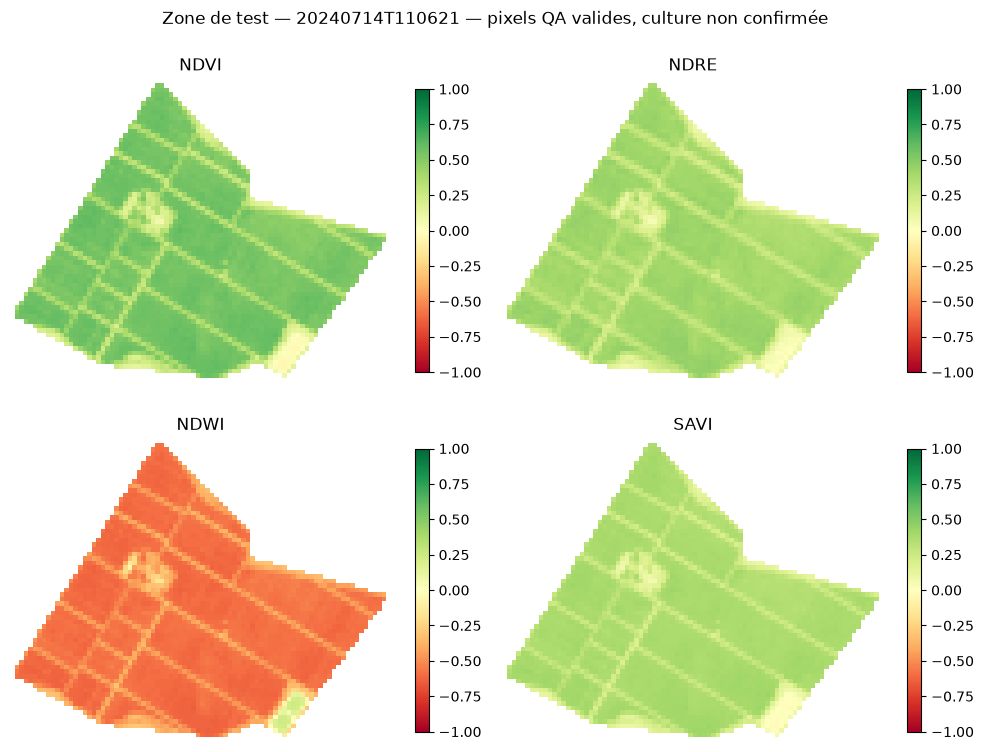

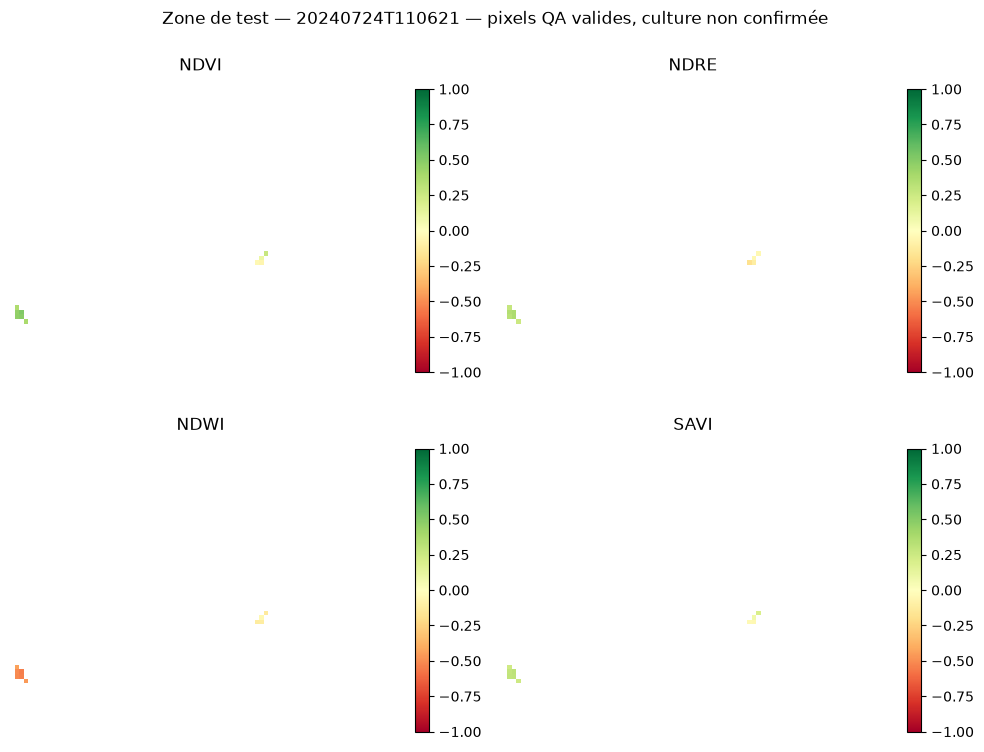

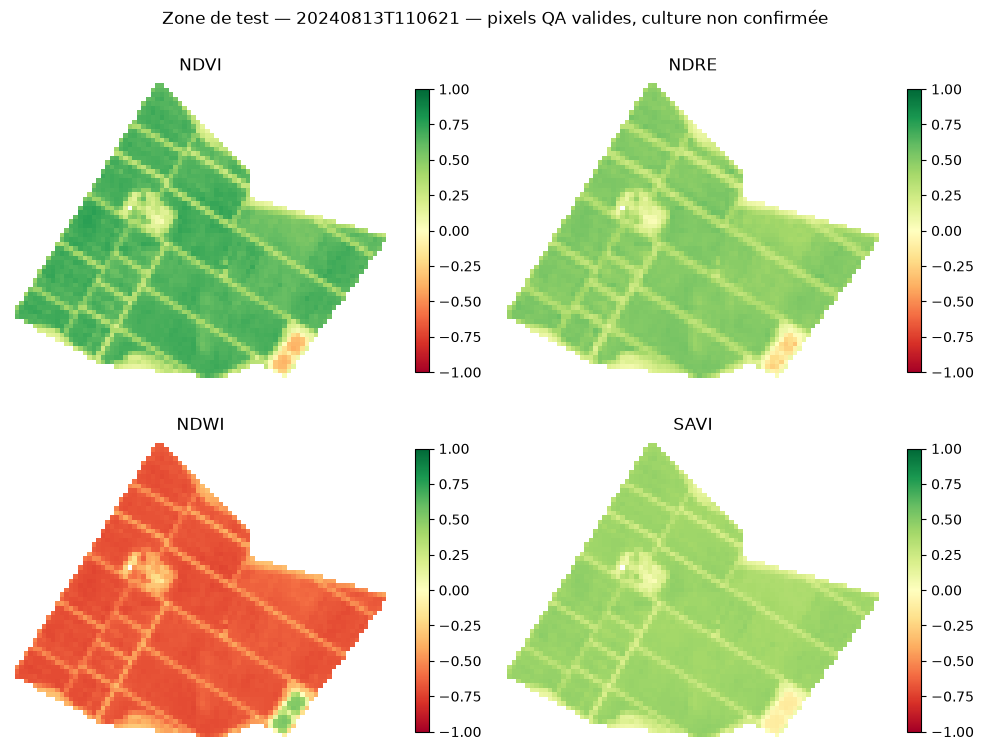

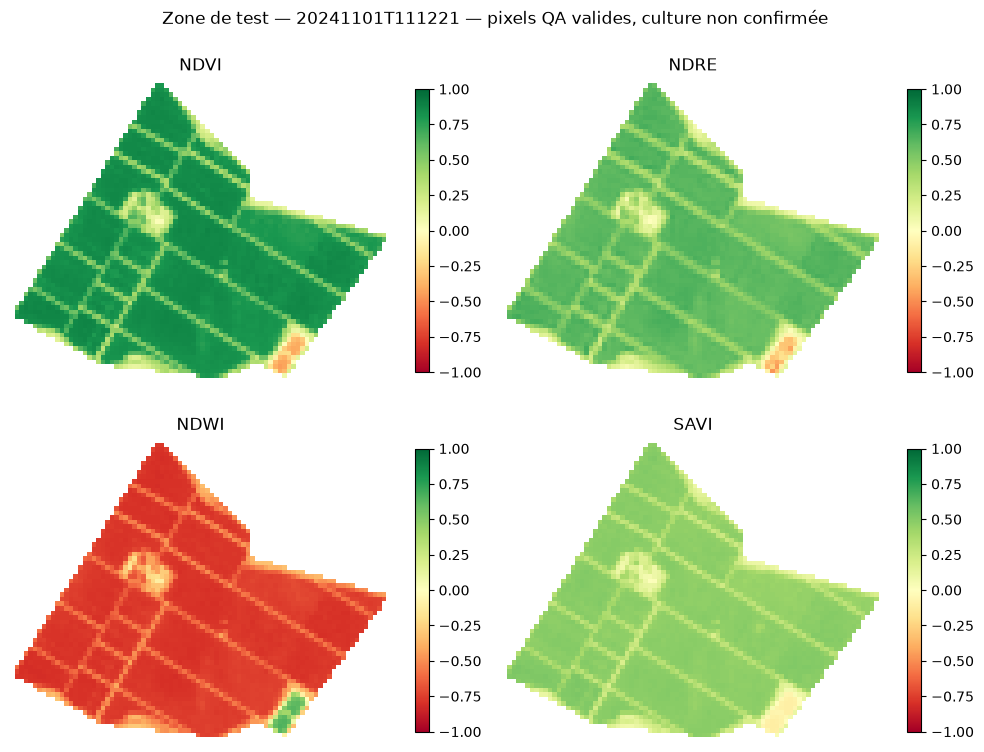

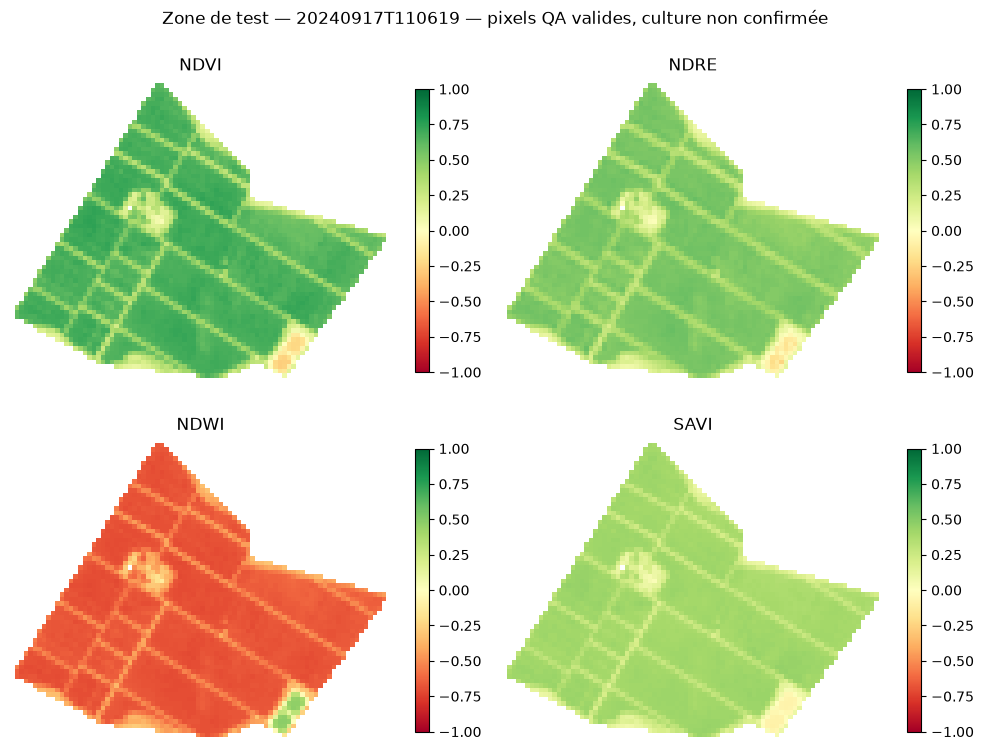

,zone_id,date,product,processing_baseline,n_zone_pixels,n_valid_pixels,valid_fraction,resolution_m,olive_presence_confirmed,usage,...,ndre_max,ndwi_mean,ndwi_median,ndwi_min,ndwi_max,savi_mean,savi_median,savi_min,savi_max,scl_counts
0,zone_test_001,2024-07-14T11:06:21.024Z,S2A_MSIL2A_20240714T110621_N0510_R137_T29SPR_2...,05.10,2923,2923,1.000000,20,False,test_technique,...,0.468031,-0.542499,-0.584705,-0.641175,0.235525,0.340081,0.372517,-0.018096,0.424559,"{""4"": 2107, ""5"": 816}"
1,zone_test_001,2024-07-24T11:06:21.024Z,S2A_MSIL2A_20240724T110621_N0511_R137_T29SPR_2...,05.11,2923,10,0.003421,20,False,test_technique,...,0.370960,-0.338970,-0.444606,-0.546330,-0.046628,0.186280,0.240788,-0.042909,0.309852,"{""3"": 2211, ""5"": 10, ""8"": 234, ""9"": 236, ""10"":..."
2,zone_test_001,2024-08-13T11:06:21.024Z,S2A_MSIL2A_20240813T110621_N0511_R137_T29SPR_2...,05.11,2923,2922,0.999658,20,False,test_technique,...,0.571327,-0.609109,-0.666330,-0.730172,0.535492,0.374485,0.414569,-0.133087,0.477835,"{""4"": 2300, ""5"": 622, ""7"": 1}"
3,zone_test_001,2024-11-01T11:12:21.024Z,S2A_MSIL2A_20241101T111221_N0511_R137_T29SPR_2...,05.11,2923,2923,1.000000,20,False,test_technique,...,0.692227,-0.695155,-0.761297,-0.811289,0.656336,0.422253,0.470510,-0.107120,0.534953,"{""4"": 2613, ""5"": 294, ""6"": 16}"
4,zone_test_001,2024-09-17T11:06:19.024Z,S2B_MSIL2A_20240917T110619_N0511_R137_T29SPR_2...,05.11,2923,2922,0.999658,20,False,test_technique,...,0.595578,-0.613797,-0.668987,-0.716085,0.482740,0.362607,0.400694,-0.086714,0.451029,"{""4"": 2333, ""5"": 589, ""7"": 1}"


Acquisitions distinctes : 5 ; aucun entraînement temporel lancé sur cette zone.


In [4]:
import zipfile
import xml.etree.ElementTree as ET
import rasterio
from rasterio.features import geometry_window, geometry_mask
from rasterio.warp import transform_geom
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling

def native_metadata(archive):
    xml=ET.fromstring(archive.read(next(n for n in archive.namelist() if n.endswith('/MTD_MSIL2A.xml'))))
    fields={}; offsets={}
    for node in xml.iter():
        tag=node.tag.split('}')[-1]
        if tag in ['PRODUCT_START_TIME','BOA_QUANTIFICATION_VALUE','PROCESSING_BASELINE']:
            fields[tag]=node.text
        if tag=='BOA_ADD_OFFSET': offsets[int(node.attrib['band_id'])]=float(node.text)
    # Les anciens produits sans offset explicite ont un offset nul.
    if float(fields['PROCESSING_BASELINE'])>=4 and not offsets:
        raise ValueError('Produit récent sans offsets XML : contrôle manuel requis')
    return fields,offsets

def local_indices(path, feature):
    geometry=feature['geometry']
    with zipfile.ZipFile(path) as archive:
        names=archive.namelist(); fields,offsets=native_metadata(archive)
        def member(band):
            resolution='10m' if band=='B08' else '20m'
            found=[n for n in names if n.endswith('_'+band+'_'+resolution+'.jp2')]
            if len(found)!=1: raise ValueError('Une seule granule attendue pour '+band)
            return '/vsizip/'+path.resolve().as_posix()+'/'+found[0]
        with rasterio.open(member('SCL')) as src:
            projected=transform_geom('EPSG:4326',src.crs,geometry)
            window=geometry_window(src,[projected])
            scl=src.read(1,window=window)
            affine=src.window_transform(window); crs=src.crs
            inside=geometry_mask([projected],out_shape=scl.shape,transform=affine,invert=True)
            full_transform=src.transform; full_shape=src.shape
        if inside.sum()==0: raise ValueError('Aucun centre de pixel dans la zone')
        valid=inside & np.isin(scl,[4,5,6])
        bands={}
        for band,band_id in [('B03',2),('B04',3),('B05',4),('B08',7),('B8A',8)]:
            with rasterio.open(member(band)) as src:
                if band=='B08':
                    with WarpedVRT(src,crs=crs,transform=full_transform,width=full_shape[1],height=full_shape[0],
                                   src_nodata=0,nodata=0,dtype='float32',resampling=Resampling.average) as aligned:
                        dn=aligned.read(1,window=window)
                else:
                    assert src.crs==crs and src.transform==full_transform and src.shape==full_shape, 'Grilles différentes'
                    dn=src.read(1,window=window)
                valid &= dn!=0
                bands[band]=(dn.astype(np.float32)+offsets.get(band_id,0))/float(fields['BOA_QUANTIFICATION_VALUE'])
        def ratio(a,b):
            den=a+b
            return np.divide(a-b,den,out=np.full_like(a,np.nan),where=np.abs(den)>1e-6)
        ndvi=ratio(bands['B08'],bands['B04'])
        ndre=ratio(bands['B8A'],bands['B05'])
        ndwi=ratio(bands['B03'],bands['B08'])
        den=bands['B08']+bands['B04']+.5
        savi=np.divide(1.5*(bands['B08']-bands['B04']),den,out=np.full_like(den,np.nan),where=np.abs(den)>1e-6)
        stack=np.stack([ndvi,ndre,ndwi,savi])
        valid &= np.isfinite(stack).all(axis=0)
        stack[:,~valid]=np.nan
        row=dict(zone_id=feature['properties']['zone_id'],date=fields['PRODUCT_START_TIME'],
                 product=path.name,processing_baseline=fields['PROCESSING_BASELINE'],
                 n_zone_pixels=int(inside.sum()),n_valid_pixels=int(valid.sum()),
                 valid_fraction=float(valid.sum()/inside.sum()),resolution_m=20,
                 olive_presence_confirmed=False,usage='test_technique')
        for band,array in zip(['ndvi','ndre','ndwi','savi'],stack):
            values=array[valid]
            for stat,fn in [('mean',np.mean),('median',np.median),('min',np.min),('max',np.max)]:
                row[band+'_'+stat]=float(fn(values)) if len(values) else None
        qa={str(int(k)):int(v) for k,v in zip(*np.unique(scl[inside],return_counts=True))}
        row['scl_counts']=json.dumps(qa)
        stamp=pd.Timestamp(fields['PRODUCT_START_TIME']).strftime('%Y%m%dT%H%M%S')
        dest=PROCESSED/('zone_test_'+stamp+'_indices.tif')
        with rasterio.open(dest,'w',driver='GTiff',height=stack.shape[1],width=stack.shape[2],
                           count=4,dtype='float32',crs=crs,transform=affine,nodata=np.nan,compress='deflate') as dst:
            dst.write(stack)
            for i,band in enumerate(['NDVI','NDRE','NDWI','SAVI'],1): dst.set_band_description(i,band)
        fig,axes=plt.subplots(2,2,figsize=(10,8))
        for ax,array,title in zip(axes.flat,stack,['NDVI','NDRE','NDWI','SAVI']):
            im=ax.imshow(array,cmap='RdYlGn',vmin=-1,vmax=1); ax.set_title(title); ax.axis('off')
            fig.colorbar(im,ax=ax,shrink=.75)
        fig.suptitle('Zone de test — '+stamp+' — pixels QA valides, culture non confirmée')
        fig.tight_layout(); fig.savefig(OUT/('zone_test_'+stamp+'_indices.png'),dpi=150)
        plt.show()
        return row

local_rows=[]
zone_path=morocco/'zone_test.geojson'
if zone_path.exists():
    collection=json.loads(zone_path.read_text(encoding='utf-8'))
    for path in sorted((RAW/'sentinel2').glob('*.zip')):
        for feature in collection['features']:
            local_rows.append(local_indices(path,feature))
    if local_rows:
        local_table=pd.DataFrame(local_rows)
        local_table.to_csv(PROCESSED/'local_zone_indices.csv',index=False)
        display(local_table)
        print('Acquisitions distinctes :',local_table.date.nunique(),'; aucun entraînement temporel lancé sur cette zone.')
else: print('Zone de test GeoJSON absente : traitement local non lancé.')

## Protocole expérimental
Deux évaluations : (1) campagnes futures sur les parcelles connues ; (2) bassin tenu
à l'écart, évalué uniquement après la validation temporelle sur les autres bassins.
Pour une série temporelle, une même parcelle peut être suivie entre campagnes ; ce n'est
pas un test d'indépendance spatiale. Le second protocole interdit le partage de bassin
et d'exploitation. Les fenêtres ne franchissent jamais les limites d'un split.
Les saisons et les échelles sont ajustées sur train seulement. Une régression harmonique
annuelle par parcelle (repli global pour parcelles inconnues) évite les z-scores mensuels
fragiles. Les valeurs manquantes ne sont pas interpolées ; une fenêtre discontinue
est rejetée. Test et validation ne servent jamais à ajuster cette normalisation.

Apprentissage sur observations confirmées normales lorsque disponibles ; sinon
apprentissage non supervisé possiblement contaminé, explicitement signalé.
Sans labels disponibles à la date de validation, optimisation par proximité d'un taux
d'alerte cible fixé à l'avance : ce critère n'est PAS une mesure de précision.
Le test est calculé après sélection de tous les choix, puis écrit dans un dossier verrouillé.

In [5]:
def read_source(name):
    paths=sorted((RAW/name).glob('*.csv'))
    return pd.concat([pd.read_csv(p) for p in paths],ignore_index=True) if paths else pd.DataFrame()
data=read_source('sentinel2'); weather=read_source('era5'); landsat=read_source('landsat')
FEATURES=['ndvi','ndre','ndwi','savi']
READY=not data.empty
if READY:
    required=['parcel_id','farm_id','basin','date','valid_fraction']+FEATURES
    assert set(required)<=set(data), f'Colonnes requises : {required}'
    data['date']=pd.to_datetime(data['date'],errors='raise')
    assert not data.duplicated(['parcel_id','date']).any(), 'Doublons à résoudre, pas à moyenner silencieusement'
    assert data.groupby('parcel_id')[['farm_id','basin']].nunique().max().max()==1
    assert data.groupby('farm_id').basin.nunique().max()==1
    display(data.dtypes.to_frame('type')); display(data.describe(include='all'))
    display(data.isna().sum().to_frame('manquants'))
    audit=data.groupby(['basin','parcel_id']).agg(first=('date','min'),last=('date','max'),n=('date','size'))
    audit.to_csv(OUT/'coverage.csv'); display(audit)
    assert data.valid_fraction.dropna().between(0,1).all()
    for f in ['ndvi','ndre','ndwi']: assert data[f].dropna().between(-1,1).all(), f
    data=data[data.valid_fraction.ge(CFG['min_valid_fraction'])].copy()
    if not weather.empty:
        weather['date']=pd.to_datetime(weather.date)
        assert not weather.duplicated(['parcel_id','date']).any()
        data=data.merge(weather[['parcel_id','date','temperature_c','precipitation_mm']],on=['parcel_id','date'],how='left',validate='one_to_one')
    data=data.sort_values(['parcel_id','date']).reset_index(drop=True)
    data['split']=np.select([data.date.lt(CFG['train_end']),data.date.lt(CFG['val_end'])],['train','val'],default='test')
    data=data[data.date.ge(CFG['start']) & data.date.lt(CFG['end'])].copy()
    if CFG['heldout_basin']:
        data.loc[data.basin.eq(CFG['heldout_basin']),'split']='excluded'
        data.loc[data.basin.eq(CFG['heldout_basin']) & data.date.ge(CFG['val_end']),'split']='spatial_test'
    if 'label' not in data: data['label']=np.nan
    assert data.label.dropna().isin([0,1]).all()
    if 'label_available_at' in data:
        available=pd.to_datetime(data.label_available_at)
        data.loc[data.split.eq('train') & available.ge(CFG['train_end']),'label']=np.nan
        data.loc[data.split.eq('val') & available.ge(CFG['val_end']),'label']=np.nan
    else:
        data['label']=np.nan
        print('Labels sans date de disponibilité ignorés pour éviter une fuite.')
    data.to_csv(PROCESSED/'series.csv',index=False)
    data[['parcel_id','farm_id','basin','date','split']].to_csv(OUT/'splits.csv',index=False)
else:
    print('BLOCAGE : aucune série Sentinel-2 extraite. Modèles et métriques non évaluables.')
display(pd.DataFrame({'source':['Sentinel-2','ERA5','Landsat'],'rows':[len(data),len(weather),len(landsat)]}))

BLOCAGE : aucune série Sentinel-2 extraite. Modèles et métriques non évaluables.


,source,rows
0,Sentinel-2,0
1,ERA5,0
2,Landsat,0


## Préparation : saisonnalité et fenêtres causales
Le z-score mesure le déficit de NDVI par rapport au cycle attendu. Les autres modèles
reçoivent les résidus saisonniers standardisés ; les ablations comparent NDVI seul,
quatre indices, puis indices + météo. Aucun remplissage depuis le futur.
Le schéma CSV accepte `label` (0/1, vide si inconnu) et `label_available_at` ; un zéro
doit être une absence de stress vérifiée, jamais une absence d'annotation.

In [6]:
def harmonic(dates):
    t=pd.DatetimeIndex(dates).dayofyear.to_numpy()/365.25*2*np.pi
    return np.column_stack([np.ones(len(t)),np.sin(t),np.cos(t),np.sin(2*t),np.cos(2*t)])
def season_fit(df, features):
    candidates=df[df.split.eq('train') & ~df.label.eq(1)].dropna(subset=features)
    confirmed=candidates[candidates.label.eq(0)]
    normal=confirmed if len(confirmed)>=20 else candidates
    if len(normal)<20: raise ValueError('Au moins 20 observations train valides requises')
    models={'global':Ridge(alpha=1).fit(harmonic(normal.date),normal[features])}
    for pid,g in normal.groupby('parcel_id'):
        if len(g)>=20 and (g.date.max()-g.date.min()).days>=365:
            models[pid]=Ridge(alpha=1).fit(harmonic(g.date),g[features])
    def residual(frame):
        r=np.full((len(frame),len(features)),np.nan)
        for pid,indices in frame.groupby('parcel_id').indices.items():
            g=frame.iloc[indices]
            expected=np.asarray(models.get(pid,models['global']).predict(harmonic(g.date))).reshape(len(g),len(features))
            r[indices]=g[features].to_numpy()-expected
        return r
    r=residual(df)
    train=df.index.isin(normal.index) & np.isfinite(r).all(axis=1)
    scaler=StandardScaler().fit(r[train])
    return scaler.transform(r),models,scaler
def windows(df,residual,length):
    x=[]; indices=[]
    # groupe par split : aucune fenêtre partagée entre train, validation et test
    for _,g in df.groupby(['parcel_id','split'],sort=False):
        ix=g.index.to_numpy()
        for end in range(length-1,len(ix)):
            selected=ix[end-length+1:end+1]
            dates=df.loc[selected,'date']
            if dates.diff().dropna().dt.days.gt(CFG['max_gap_days']).any(): continue
            if not np.isfinite(residual[selected]).all(): continue
            x.append(residual[selected].ravel()); indices.append(ix[end])
    if not x: raise ValueError('Aucune fenêtre valide : vérifier dates, couverture et longueur')
    return np.array(x,dtype=np.float32),np.array(indices)

## Modèle 1 — z-score NDVI
Baseline statistique transparente : score = opposé du dernier résidu NDVI standardisé.
Une baisse inhabituelle donne un score élevé. Le seuil est choisi en validation.
Les hausses inhabituelles ne sont pas ciblées par cette baseline de déficit.
## Modèle 2 — Isolation Forest
Modèle non supervisé multivarié : isolement des fenêtres atypiques. Recherche sur
`n_estimators`, `max_samples` et `contamination` sans consulter le test.
## Modèle 3 — One-Class SVM
Frontière de normalité RBF ; recherche sur `gamma` et `nu`. Coût quadratique potentiel,
limitation déterministe de l'apprentissage à 5 000 fenêtres pour les deux modèles ML.
## Modèle 4 — autoencoder
Reconstruction d'une fenêtre aplatie, architecture dense, perte MSE, AdamW,
recherche sur dimension latente, learning rate, poids de régularisation et fenêtre.
Checkpoint choisi sur erreur de reconstruction des données de validation normales
connues (ou non étiquetées), jamais sur test. Ce choix suppose la majorité normale.

In [7]:
class Autoencoder(nn.Module):
    def __init__(self, size, latent):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(size,32),nn.ReLU(),nn.Linear(32,latent),nn.ReLU(),nn.Linear(latent,32),nn.ReLU(),nn.Linear(32,size))
    def forward(self,x): return self.net(x)
def fit_method(name,train,val,params):
    rng=np.random.default_rng(SEED)
    sample=train[rng.choice(len(train),min(5000,len(train)),replace=False)]
    if name=='zscore': return None,[]
    if name=='isolation': return IsolationForest(random_state=SEED,n_jobs=1,**params).fit(sample),[]
    if name=='svm': return OneClassSVM(kernel='rbf',**params).fit(sample),[]
    torch.manual_seed(SEED)
    model=Autoencoder(train.shape[1],params['latent'])
    optimizer=torch.optim.AdamW(model.parameters(),lr=params['lr'],weight_decay=params['weight_decay'])
    a=torch.tensor(train); b=torch.tensor(val)
    best=float('inf'); checkpoint=None; history=[]; stale=0
    for epoch in range(100):
        model.train(); losses=[]
        for batch in torch.randperm(len(a)).split(128):
            optimizer.zero_grad(); loss=((model(a[batch])-a[batch])**2).mean()
            loss.backward(); optimizer.step(); losses.append(loss.item())
        model.eval()
        with torch.no_grad(): v=((model(b)-b)**2).mean().item()
        history.append({'epoch':epoch,'train':float(np.mean(losses)),'validation':v})
        if v<best-1e-6: best=v; checkpoint=copy.deepcopy(model.state_dict()); stale=0
        else: stale+=1
        if stale>=10: break
    model.load_state_dict(checkpoint)
    return model,history
def score(name,model,x,n_features):
    if name=='zscore': return -x[:,-n_features]
    if name in ['isolation','svm']: return -model.score_samples(x)
    model.eval()
    with torch.no_grad(): return ((model(torch.tensor(x))-torch.tensor(x))**2).mean(dim=1).numpy()
def metrics(y,s,threshold):
    known=np.isfinite(y); y=y[known].astype(int); s=s[known]
    if not len(y): return dict(n_labelled=0,precision=None,recall=None,f1=None,ap=None,auc=None)
    pred=s>threshold
    tp=int(((y==1)&pred).sum()); fp=int(((y==0)&pred).sum()); fn=int(((y==1)&~pred).sum())
    precision=tp/(tp+fp) if tp+fp else None
    recall=tp/(tp+fn) if tp+fn else None
    f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else None
    return dict(n_labelled=len(y),n_positive=int(y.sum()),tp=tp,fp=fp,fn=fn,
                precision=precision,recall=recall,f1=f1,
                ap=float(average_precision_score(y,s)) if len(set(y))==2 else None,
                auc=float(roc_auc_score(y,s)) if len(set(y))==2 else None,
                confusion=confusion_matrix(y,pred,labels=[0,1]).tolist())
def threshold_validation(scores,labels):
    thresholds=np.unique(np.quantile(scores,np.linspace(.80,.995,40)))
    labelled=np.isfinite(labels)
    supervised=labelled.sum()>0 and len(np.unique(labels[labelled]))==2
    def objective(t):
        if supervised: return metrics(labels,scores,t)['f1'] or 0.
        return -abs(float((scores>t).mean())-CFG['target_alert_rate'])
    selected=max(thresholds,key=objective)
    return float(selected),float(objective(selected)), 'F1 validation' if supervised else 'taux alerte cible (pas une performance)'

## Optimisation et ablations
Budget TPE fixé à 12 essais par méthode et ablation ; 3 longueurs de fenêtre (1,3,6).
La comparaison finale utilise l'intersection des observations de test accessibles à
tous les gagnants, pour que les métriques portent sur les mêmes exemples.
L'agrégation 10 jours, le filtre nuage et la qualité sont fixés avant extraction ; les
variantes 5/15 jours demandent des extractions et expériences séparées, sans retoucher
les choix après le test. Pas de lissage par défaut pour préserver les ruptures.

In [8]:
winners=[]; trials_log=[]
if READY and RUN_EXPERIMENT:
    data=data.reset_index(drop=True)
    assert {'train','val','test'}<=set(data.split), 'Splits temporels incomplets'
    ablations={'ndvi':['ndvi'],'indices':FEATURES}
    if {'temperature_c','precipitation_mm'}<=set(data):
        ablations['meteo']=FEATURES+['temperature_c','precipitation_mm']
    for ablation,features in ablations.items():
        residual,season,scaler=season_fit(data,features)
        for name in ['zscore','isolation','svm','autoencoder']:
            if name=='zscore' and ablation!='ndvi': continue
            best_holder={}
            def objective(trial):
                length=trial.suggest_categorical('length',[1,3,6])
                x,ix=windows(data,residual,length)
                subset=data.loc[ix]; tr=subset.split.eq('train').to_numpy(); va=subset.split.eq('val').to_numpy()
                tr &= ~subset.label.eq(1).to_numpy()
                normal_val=va & ~subset.label.eq(1).to_numpy()
                confirmed_train=tr & subset.label.eq(0).to_numpy()
                confirmed_val=va & subset.label.eq(0).to_numpy()
                if confirmed_train.sum()>=20: tr=confirmed_train
                if confirmed_val.sum()>=5: normal_val=confirmed_val
                if tr.sum()<20 or normal_val.sum()<5: raise optuna.TrialPruned('Couverture insuffisante')
                params={}
                if name=='isolation': params=dict(n_estimators=trial.suggest_categorical('n_estimators',[100,250]),max_samples=trial.suggest_categorical('max_samples',[.5,1.]),contamination=trial.suggest_float('contamination',.01,.1))
                if name=='svm': params=dict(gamma=trial.suggest_float('gamma',1e-4,1.,log=True),nu=trial.suggest_float('nu',.01,.2))
                if name=='autoencoder': params=dict(latent=trial.suggest_categorical('latent',[2,4,8]),lr=trial.suggest_float('lr',1e-4,1e-2,log=True),weight_decay=trial.suggest_float('weight_decay',1e-6,1e-2,log=True))
                model,history=fit_method(name,x[tr],x[normal_val],params)
                scores=score(name,model,x[va],len(features))
                threshold,value,criterion=threshold_validation(scores,subset.loc[va,'label'].to_numpy(float))
                if not best_holder or value>best_holder['value']:
                    best_holder.update(value=value,name=name,ablation=ablation,features=features,params=params,length=length,threshold=threshold,criterion=criterion,model=model,history=history,season=season,scaler=scaler,x=x,ix=ix)
                return value
            study=optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=SEED))
            study.optimize(objective,n_trials=CFG['trials'])
            study.trials_dataframe().to_csv(OUT/f'trials_{ablation}_{name}.csv',index=False)
            if best_holder: winners.append(best_holder)
    print('Modèles sélectionnés uniquement sur validation :',len(winners))
else: print('Optimisation non exécutée : séries réelles absentes.')

Optimisation non exécutée : séries réelles absentes.


## Comparaison finale et indicateurs
Précision/rappel/F1 ponctuels sur labels confirmés ; AP et AUC seulement si les deux
classes existent. Les valeurs non évaluables restent nulles. Taux d'alertes et effectifs
sont toujours affichés mais ne prouvent pas la fiabilité.

Les métriques événementielles nécessitent `events.csv` (événements confirmés) et
`surveillance.csv` (intervalles de surveillance exhaustive, dates de fin inclusives).
Les alertes consécutives sont regroupées en épisodes, puis appariées une à une aux
événements avec la tolérance prédéfinie. Une alerte hors surveillance n'est pas un faux
positif connu. Délai = jours après début, ramené à zéro pour une alerte anticipée.
Stabilité interannuelle : dispersion du taux d'alertes par campagne, descriptive et
potentiellement affectée par des changements réels de stress ou de couverture.

In [9]:
def event_metrics(pred):
    events=pd.read_csv(morocco/'events.csv'); coverage=pd.read_csv(morocco/'surveillance.csv')
    if coverage.empty: return {'event_precision':None,'event_recall':None,'event_f1':None,'mean_delay_days':None,'fp_per_parcel':None,'reason':'Surveillance exhaustive absente'}
    for c in ['start','end']: coverage[c]=pd.to_datetime(coverage[c])
    for c in ['onset','end','available_at']: events[c]=pd.to_datetime(events[c])
    assert not events.event_id.duplicated().any()
    lo,hi=pred.date.min(),pred.date.max()
    coverage=coverage[(coverage.end>=lo)&(coverage.start<=hi)].copy()
    coverage['start']=coverage.start.clip(lower=lo)
    coverage['end']=coverage.end.clip(upper=hi)
    episodes=[]; eligible=[]; parcels=set()
    for pid,group in pred.groupby('parcel_id'):
        cov=coverage[coverage.parcel_id.eq(pid)]
        if cov.empty: continue
        parcels.add(pid)
        monitored=group.date.map(lambda d: ((cov.start<=d)&(cov.end>=d)).any())
        dates=group.loc[monitored & group.alert,'date'].sort_values()
        last=None
        for d in dates:
            if last is None or (d-last).days>CFG['max_gap_days']: episodes.append((pid,d))
            last=d
        for row in events[events.parcel_id.eq(pid) & events.confirmed.eq(1)].itertuples():
            tol=pd.Timedelta(days=CFG['event_tolerance_days'])
            if ((cov.start<=row.onset-tol)&(cov.end>=row.end+tol)).any(): eligible.append(row)
    used=set(); delays=[]
    # Ordre chronologique et une seule correspondance par épisode et événement.
    for pid,d in sorted(episodes,key=lambda e:e[1]):
        candidates=[e for e in eligible if e.parcel_id==pid and e.event_id not in used and e.onset-pd.Timedelta(days=CFG['event_tolerance_days'])<=d<=e.end+pd.Timedelta(days=CFG['event_tolerance_days'])]
        if candidates:
            e=min(candidates,key=lambda e:abs((d-e.onset).days)); used.add(e.event_id); delays.append(max(0,(d-e.onset).days))
    tp=len(used); fp=len(episodes)-tp; fn=len(eligible)-tp
    return dict(event_precision=tp/len(episodes) if episodes else None,event_recall=tp/len(eligible) if eligible else None,event_f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else None,mean_delay_days=float(np.mean(delays)) if delays else None,fp_per_parcel=fp/len(parcels) if parcels else None,n_events=len(eligible),n_episodes=len(episodes),n_monitored_parcels=len(parcels))
results=[]
if winners:
    # Verrouillage avant le premier calcul des scores de test.
    lock=OUT/'locked_protocol.json'
    if lock.exists(): raise RuntimeError('Expérience déjà verrouillée : conserver ce dossier et choisir un nouveau dossier outputs pour une nouvelle expérience.')
    choices=[{k:w[k] for k in ['name','ablation','params','length','threshold','criterion']} for w in winners]
    lock.write_text(json.dumps({'config':CFG,'choices':choices,'seed':SEED},indent=2))
    for split in ['test','spatial_test']:
        sets=[set(w['ix'][data.loc[w['ix'],'split'].eq(split)]) for w in winners]
        common=sorted(set.intersection(*sets))
        if not common: continue
        for w in winners:
            positions=np.array([np.flatnonzero(w['ix']==i)[0] for i in common])
            start=time.perf_counter(); s=score(w['name'],w['model'],w['x'][positions],len(w['features'])); seconds=time.perf_counter()-start
            pred=data.loc[common,['parcel_id','farm_id','basin','date','label']].copy()
            pred['score']=s; pred['alert']=s>w['threshold']
            tag=w['ablation']+'_'+w['name']
            pred.to_csv(OUT/f'predictions_{split}_{tag}.csv',index=False)
            row=dict(split=split,model=w['name'],ablation=w['ablation'],n=len(s),alert_rate=float(pred.alert.mean()),inference_seconds=seconds,**metrics(pred.label.to_numpy(float),s,w['threshold']),**event_metrics(pred))
            annual=pred.assign(year=pred.date.dt.year).groupby('year').alert.agg(['mean','count'])
            annual.to_csv(OUT/f'annual_{split}_{tag}.csv')
            row['annual_alert_rate_std']=float(annual['mean'].std()) if len(annual)>1 else None
            results.append(row)
    display(pd.DataFrame(results))
    pd.DataFrame(results).to_csv(OUT/'comparison.csv',index=False)
else: print('Comparaison indisponible : aucun entraînement réel effectué.')

Comparaison indisponible : aucun entraînement réel effectué.


## Historique Landsat indépendant
Le capteur est conservé séparément. Cette courbe historique aide à inspecter la
saisonnalité à 30 m, sans supposer l'équivalence radiométrique à Sentinel-2.
La fusion nécessiterait une calibration sur dates communes et parcelles compatibles.

In [10]:
if not landsat.empty:
    landsat['date']=pd.to_datetime(landsat.date)
    assert not landsat.duplicated(['parcel_id','date']).any()
    history=landsat[landsat.valid_fraction.ge(CFG['min_valid_fraction'])].copy()
    history['month']=history.date.dt.month
    baseline=history[history.date.lt(CFG['train_end'])].groupby(['parcel_id','month']).ndvi.agg(['mean','std','count'])
    baseline.to_csv(OUT/'landsat_historical_baseline.csv'); display(baseline)
else: print('Historique Landsat non extrait : baseline non calculée.')

Historique Landsat non extrait : baseline non calculée.


## Sauvegarde et vérifications
Export des transformations saisonnières, modèles, seuils, configuration, splits,
prédictions, courbes et versions. Pas d'ONNX ici : export optionnel, non nécessaire
à cette phase expérimentale. Le chronométrage mesure le scoring en mémoire sur les
fenêtres de test communes, hors téléchargement et prétraitement.

In [11]:
for w in winners:
    tag=w['ablation']+'_'+w['name']
    bundle={k:w[k] for k in ['name','features','params','length','threshold','season','scaler']}
    if w['name']=='autoencoder':
        torch.save(w['model'].state_dict(),OUT/f'{tag}.pt')
        pd.DataFrame(w['history']).to_csv(OUT/f'{tag}_learning.csv',index=False)
        pd.DataFrame(w['history']).set_index('epoch').plot(); plt.title(tag); plt.ylabel('MSE'); plt.show()
    else: bundle['model']=w['model']
    joblib.dump(bundle,OUT/f'{tag}.joblib')
versions={d.metadata['Name']:d.version for d in importlib.metadata.distributions() if d.metadata['Name']}
(META/'environment.json').write_text(json.dumps({'python':sys.version,'platform':platform.platform(),'packages':versions,'seed':SEED},indent=2))
(OUT/'status.json').write_text(json.dumps({'real_data_available':bool(READY or local_rows),'training_series_available':READY,'local_acquisitions':len(local_rows),'trained_models':len(winners),'metrics_available':bool(results),'blockers':[] if READY else ['Parcelles oléicoles et groupes non confirmés','Séries multi-temporelles insuffisantes','Vérité terrain et surveillance à constituer']},indent=2,ensure_ascii=False))
# Tests ciblés sur petites valeurs artificielles : pas des résultats expérimentaux.
assert metrics(np.array([1.,0.,np.nan]),np.array([2.,0.,9.]),1)['f1']==1
assert metrics(np.array([np.nan]),np.array([2.]),1)['precision'] is None
toy=pd.DataFrame({'parcel_id':['a']*6,'split':['train']*3+['test']*3,'date':pd.date_range('2020-01-01',periods=6,freq='10D')})
wx,wi=windows(toy,np.arange(6,dtype=float).reshape(-1,1),3)
assert wi.tolist()==[2,5] and wx.tolist()==[[0.,1.,2.],[3.,4.,5.]]
toy.loc[2,'date']=pd.Timestamp('2020-03-01')
_,wi=windows(toy,np.ones((6,1)),3); assert wi.tolist()==[5]
if READY:
    assert data[data.split.eq('train')].date.max()<pd.Timestamp(CFG['train_end'])
    assert data[data.split.eq('val')].date.max()<pd.Timestamp(CFG['val_end'])
    if CFG['heldout_basin']:
        a=set(data[data.split.isin(['train','val'])].farm_id)
        b=set(data[data.split.eq('spatial_test')].farm_id)
        assert not a&b
print('Tests de métriques, frontières temporelles et discontinuités : OK')

Tests de métriques, frontières temporelles et discontinuités : OK


## Interprétation, limites et prochaines étapes
Aucun meilleur modèle ne peut être annoncé sans séries extraites et vérité terrain.
L'absence de labels permet seulement de comparer taux d'alerte, stabilité et coûts,
pas de conclure à la précision de détection. Les saisons atypiques, sols nus, cultures
intercalaires, taille des parcelles, pluies et irrigation peuvent expliquer des alertes.
La météo peut contextualiser le signal mais ne révèle pas la cause du stress.

Avant une étude opérationnelle : constituer les polygones et visites marocaines,
fixer campagnes et bassin exclus, vérifier couverture/pixels mixtes, examiner les
labels datés, exécuter l'extraction puis Run All. Une baseline fiable demande plusieurs
cycles annuels. Préenregistrer un protocole distinct pour tester agrégation 5/15 jours,
persistance et lissage causal. Conserver ce test intact pour toute comparaison ultérieure.